In [2]:
import numpy as np

In [3]:
import seaborn as sns

In [4]:
dataset=sns.load_dataset('penguins')

In [5]:
dataset.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [8]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [9]:
dataset.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [11]:
dataset.isnull().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


In [17]:
dataset.duplicated().sum()

np.int64(0)

In [19]:
dataset.dropna(subset=[
 'bill_length_mm',
 'bill_depth_mm',
 'flipper_length_mm',
 'body_mass_g'])

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,Female
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [20]:
dataset.dropna(subset=['sex'])

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,Female
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [21]:
import matplotlib.pyplot as plt

<Axes: xlabel='species', ylabel='body_mass_g'>

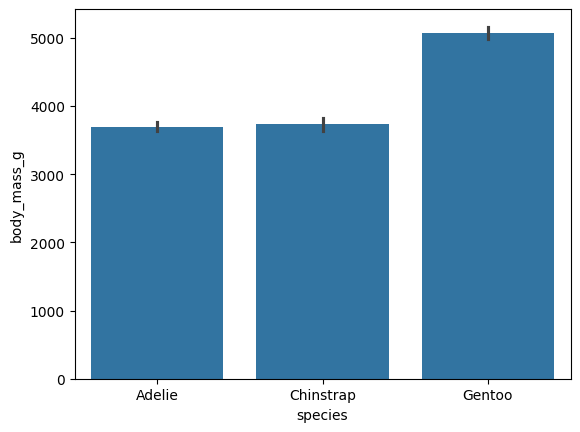

In [29]:
sns.barplot(data=dataset, x="species", y="body_mass_g")

<Axes: xlabel='species', ylabel='count'>

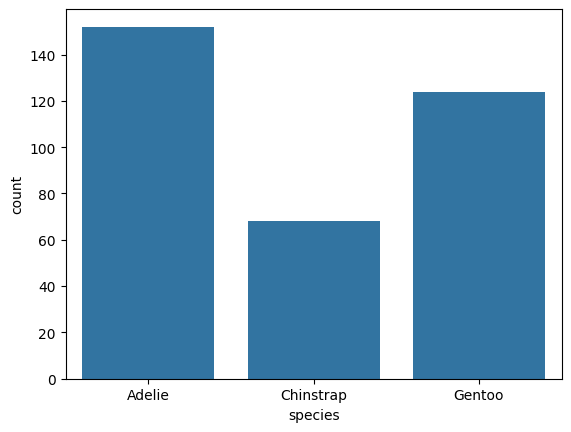

In [31]:
sns.countplot(data=dataset, x='species')

<Axes: xlabel='Count', ylabel='bill_length_mm'>

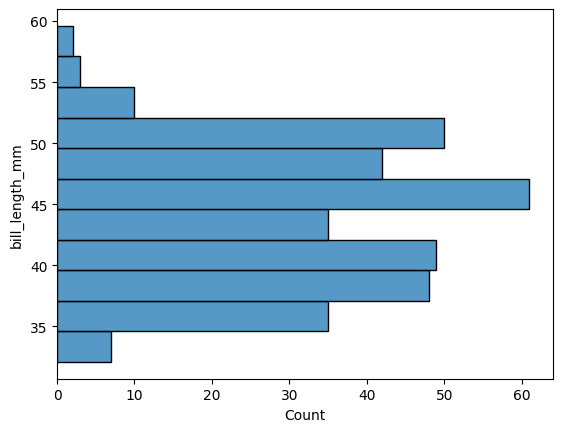

In [38]:
sns.histplot(data=dataset,y='bill_length_mm')

it is right skewed


<Axes: xlabel='species', ylabel='bill_length_mm'>

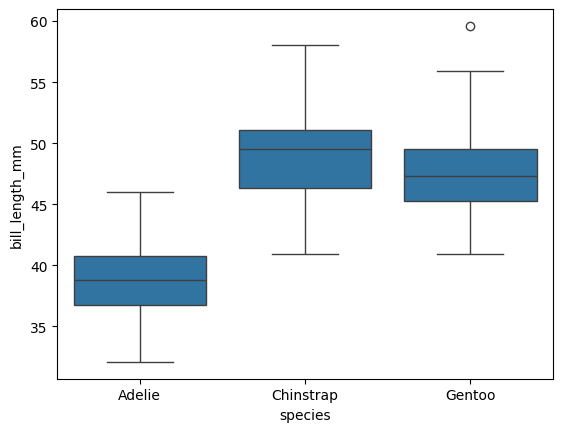

In [35]:
sns.boxplot(data=dataset,x='species',y='bill_length_mm')

TASK 04

In [40]:
q1=dataset['bill_length_mm'].quantile(0.25)

In [41]:
q3=dataset['bill_length_mm'].quantile(0.75)

In [42]:
iqr=q3-q1

In [43]:
lower=q1-1.5*iqr

In [44]:
upper=q3+1.5*iqr

In [47]:
outlier=dataset[(dataset['bill_length_mm']<lower) | (dataset['bill_length_mm']>upper)]

In [48]:
print(len(outlier))

0


In [49]:
from scipy import stats

In [50]:
dataset['zscore']=stats.zscore(dataset['bill_length_mm'])

In [53]:
outliers_z=stats.zscore(dataset['bill_length_mm'])

In [55]:
outliers_z = dataset[abs(dataset["zscore"]) > 3]

print(len(outliers_z))

0


<Axes: xlabel='bill_length_mm', ylabel='bill_depth_mm'>

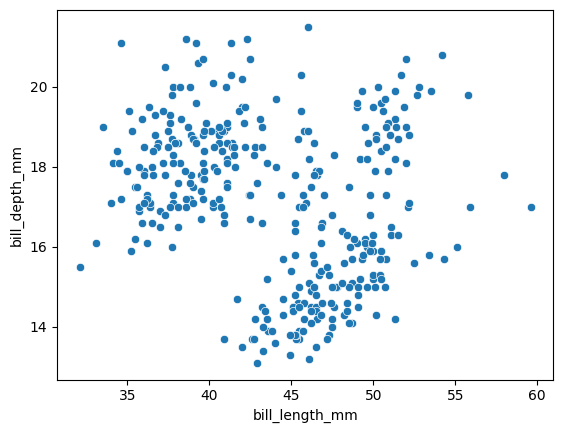

In [58]:
sns.scatterplot(data=dataset,x='bill_length_mm',y='bill_depth_mm')

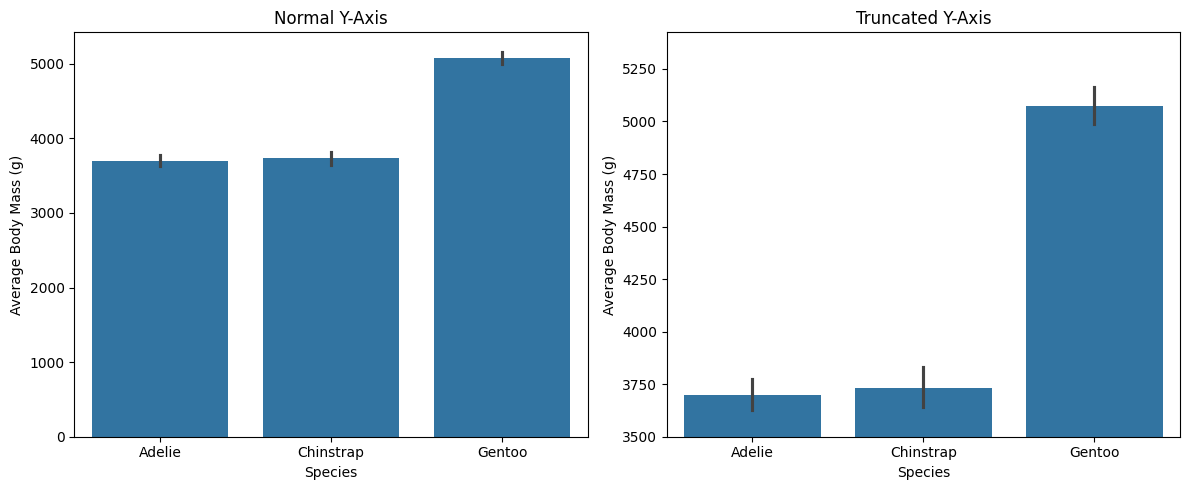

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


sns.barplot(data=dataset, x="species", y="body_mass_g", ax=axes[0])
axes[0].set_title("Normal Y-Axis")
axes[0].set_xlabel("Species")
axes[0].set_ylabel("Average Body Mass (g)")

sns.barplot(data=dataset, x="species", y="body_mass_g", ax=axes[1])
axes[1].set_ylim(bottom=3500)
axes[1].set_title("Truncated Y-Axis")
axes[1].set_xlabel("Species")
axes[1].set_ylabel("Average Body Mass (g)")

plt.tight_layout()
plt.show()

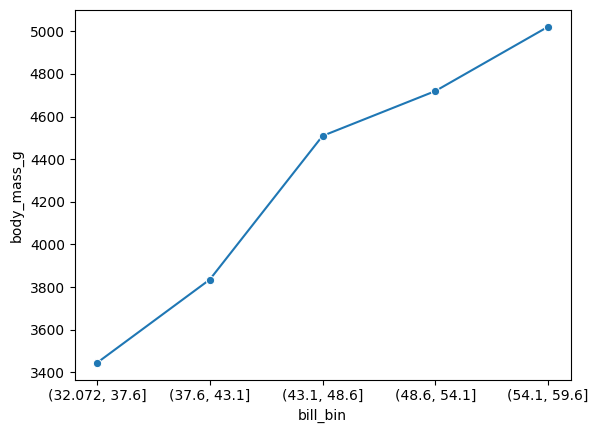

In [62]:
dataset["bill_bin"] = pd.cut(dataset["bill_length_mm"], bins=5)

avg_mass = dataset.groupby("bill_bin", observed=True)["body_mass_g"].mean().reset_index()

avg_mass["bill_bin"] = avg_mass["bill_bin"].astype(str)

sns.lineplot(data=avg_mass, x="bill_bin", y="body_mass_g", marker="o")
plt.show()

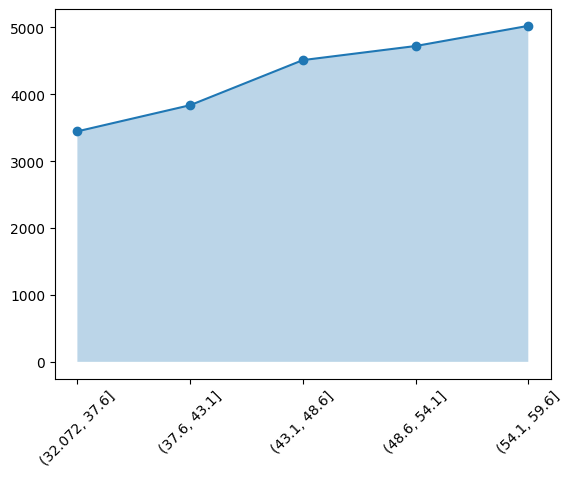

In [63]:
x = range(len(avg_mass))

plt.plot(x, avg_mass["body_mass_g"], marker="o")
plt.fill_between(x, avg_mass["body_mass_g"], alpha=0.3)
plt.xticks(x, avg_mass["bill_bin"], rotation=45)
plt.show()